In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def getRc(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    return (n_ss-n_os)/(n_ss+n_os)

In [5]:
def getRcs(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    return (n_ss-n_os)/(n_ss+n_os)

In [6]:
def getRcErr(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    n_unweighted = dataframe[dataframe.b==1].shape[0] + dataframe[dataframe.b==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [7]:
def getRcsErr(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    n_unweighted = dataframe[dataframe.bs==1].shape[0] + dataframe[dataframe.bs==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [8]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [104]:
def w_norm_per_xbin(h,x,y):
    w = np.empty([len(x)-1,len(y)-1])
    for i in range(0,len(x)-1):
        for j in range(0,len(y)-1):
            w[i][j] = h[i][j]/sum(h[i]) + 10**-50
    return w

In [9]:
observables1 = ['pt','b','dr','z','epair','w','reject','pt1','pt2','qlead','qsublead','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects','pt1s','pt2s','qleads','qsubleads','y1s','y2s','phi1s','phi2s']

In [94]:
df = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),'bs!=-9 and b!=-9 and reject<=0 and rejects<=0')

In [131]:
df_all_reco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),'bs!=-9 and reject<=0 and rejects<=0')

In [101]:
distance1 = []
distance2 = []
for i in range(0,df.shape[0]):
    phi1small = min(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi1large = max(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi2small = min(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    phi2large = max(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df.iloc[i]['phi1'], df.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df.iloc[i]['y1']-df.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df.iloc[i]['y2']-df.iloc[i]['y2s'])**2))
df['distance1'] = distance1
df['distance2'] = distance2

In [102]:
df = applyCut(df, 'distance1 < 0.02 and distance2 < 0.02')

In [103]:
df.shape[0]

65578

In [105]:
h,x,y = np.histogram2d(df['pt'],df['pts'], bins=([5,10,15,20,25,30,40]), weights=df['w'], density=True)

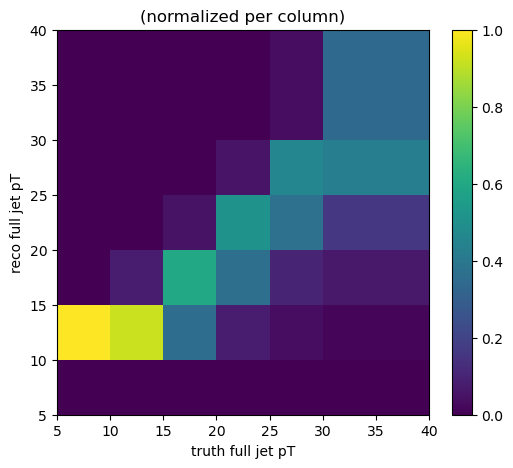

In [106]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('truth full jet pT')
plt.ylabel('reco full jet pT')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

In [107]:
rc_00 = getRc(applyCut(df,'15<pt<20'))
rc_err_00 = getRcErr(applyCut(df,'15<pt<20'))

In [108]:
rc_0 = getRc(applyCut(df,'20<pt<25'))
rc_err_0 = getRcErr(applyCut(df,'20<pt<25'))

In [109]:
rc_1 = getRc(applyCut(df,'25<pt<30'))
rc_err_1 = getRcErr(applyCut(df,'25<pt<30'))

In [110]:
rc_2 = getRc(applyCut(df,'30<pt<40'))
rc_err_2 = getRcErr(applyCut(df,'30<pt<40'))

In [111]:
rcs_00 = getRcs(applyCut(df,'15<pt<20'))
rcs_err_00 = getRcsErr(applyCut(df,'15<pt<20'))

In [112]:
rcs_0 = getRcs(applyCut(df,'20<pt<25'))
rcs_err_0 = getRcsErr(applyCut(df,'20<pt<25'))

In [113]:
rcs_1 = getRcs(applyCut(df,'25<pt<30'))
rcs_err_1 = getRcsErr(applyCut(df,'25<pt<30'))

In [114]:
rcs_2 = getRcs(applyCut(df,'30<pt<40'))
rcs_err_2 = getRcsErr(applyCut(df,'30<pt<40'))

Text(0.5, 1.0, 'Matching cut: truth pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

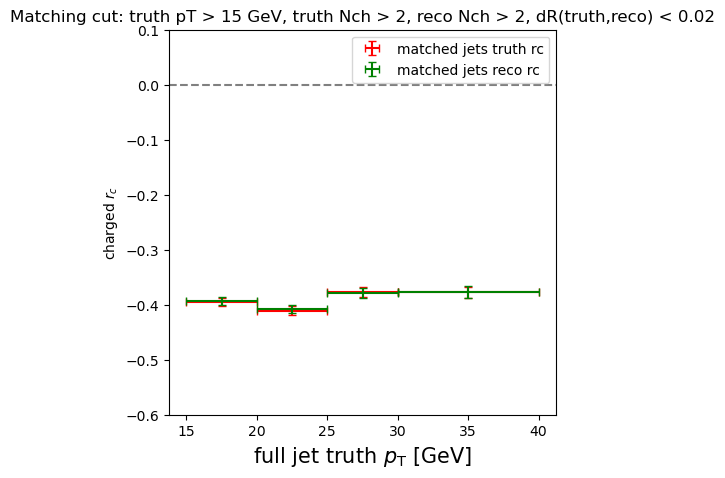

In [115]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00, rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00, rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='matched jets truth rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='matched jets reco rc')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,0.1)
plt.legend()
plt.title('Matching cut: truth pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [116]:
rc_00 = getRc(applyCut(df,'15<pts<20'))
rc_err_00 = getRcErr(applyCut(df,'15<pts<20'))

In [117]:
rc_0 = getRc(applyCut(df,'20<pts<25'))
rc_err_0 = getRcErr(applyCut(df,'20<pts<25'))

In [118]:
rc_1 = getRc(applyCut(df,'25<pts<30'))
rc_err_1 = getRcErr(applyCut(df,'25<pts<30'))

In [119]:
rc_2 = getRc(applyCut(df,'30<pts<40'))
rc_err_2 = getRcErr(applyCut(df,'30<pts<40'))

In [120]:
rcs_00 = getRcs(applyCut(df,'15<pts<20'))
rcs_err_00 = getRcsErr(applyCut(df,'15<pts<20'))

In [121]:
rcs_0 = getRcs(applyCut(df,'20<pts<25'))
rcs_err_0 = getRcsErr(applyCut(df,'20<pts<25'))

In [122]:
rcs_1 = getRcs(applyCut(df,'25<pts<30'))
rcs_err_1 = getRcsErr(applyCut(df,'25<pts<30'))

In [123]:
rcs_2 = getRcs(applyCut(df,'30<pts<40'))
rcs_err_2 = getRcsErr(applyCut(df,'30<pts<40'))

In [132]:
rcs_00_allreco = getRcs(applyCut(df_all_reco,'15<pts<20'))
rcs_err_00_allreco = getRcsErr(applyCut(df_all_reco,'15<pts<20'))

In [133]:
rcs_0_allreco = getRcs(applyCut(df_all_reco,'20<pts<25'))
rcs_err_0_allreco = getRcsErr(applyCut(df_all_reco,'20<pts<25'))

In [134]:
rcs_1_allreco = getRcs(applyCut(df_all_reco,'25<pts<30'))
rcs_err_1_allreco = getRcsErr(applyCut(df_all_reco,'25<pts<30'))

In [135]:
rcs_2_allreco = getRcs(applyCut(df_all_reco,'30<pts<40'))
rcs_err_2_allreco = getRcsErr(applyCut(df_all_reco,'30<pts<40'))

Text(0.5, 1.0, 'Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

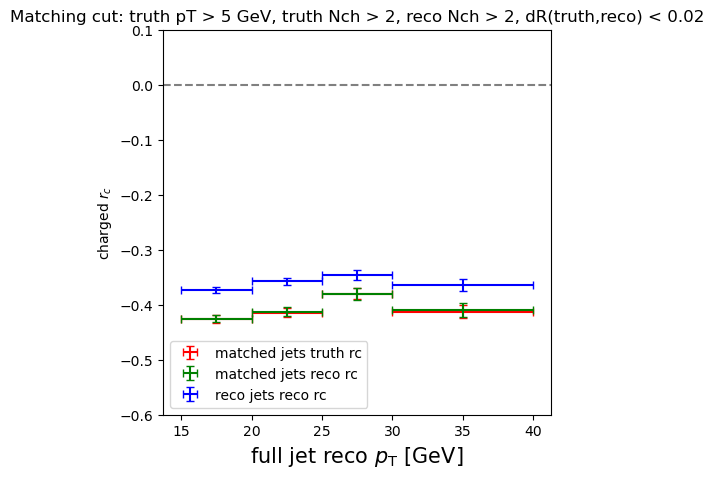

In [136]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00, rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00, rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='matched jets truth rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='matched jets reco rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00_allreco, rcs_0_allreco, rcs_1_allreco, rcs_2_allreco], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00_allreco, rcs_err_0_allreco, rcs_err_1_allreco, rcs_err_2_allreco], capsize=3, color='b', ls='none', label='reco jets reco rc')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,0.1)
plt.legend()
plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')